# Lógica difusa. - PROBLEMA DE LA PROPINA -    

Vamos a intentar enfocar la decisión de dar propina en función de dos elementos:    

- La calidad del servicio.
- La calidad de la comida.


In [1]:
# Importamos librerias necesarias.
# pip install -U scikit-fuzzy networkx
import numpy as np
import skfuzzy as fuzz
import matplotlib.pyplot as plt
from skfuzzy import control as ctrl


### Variables y universo de discurso

En lógica difusa, una **variable** es una magnitud del problema sobre la que queremos razonar. En el problema de la propina:

- **Variables de entrada (antecedentes):** la *calidad de la comida* y la *calidad del servicio*. Son los datos que conocemos.
- **Variable de salida (consecuente):** la *propina*. Es lo que el sistema tiene que decidir.

El **universo de discurso** es el rango de valores posibles que puede tomar cada variable:

- Calidad y servicio: puntuación de **0 a 10**.
- Propina: porcentaje de **0 % a 25 %**.

En `scikit-fuzzy` el universo se define con un array de NumPy (p. ej. `np.arange(0, 11, 1)` genera los valores 0, 1, 2, …, 10). Las entradas se crean con `ctrl.Antecedent` y la salida con `ctrl.Consequent`.

In [2]:
# 1. Variables (universo de discurso)
calidad = ctrl.Antecedent(np.arange(0, 11, 1), 'calidad')
servicio = ctrl.Antecedent(np.arange(0, 11, 1), 'servicio')
propina = ctrl.Consequent(np.arange(0, 26, 1), 'propina')

### Funciones de pertenencia

En lógica clásica un valor pertenece o no pertenece a un conjunto (sí/no). En lógica difusa cada variable se divide en **conjuntos difusos** o **etiquetas lingüísticas**, y un valor puede pertenecer a cada uno *en cierto grado*:

- Calidad y servicio: *mala*, *aceptable*, *buena*.
- Propina: *baja*, *media*, *alta*.

Una **función de pertenencia** indica el **grado de pertenencia** de cada valor del universo a una etiqueta. Ese grado es un número entre **0** (no pertenece nada) y **1** (pertenece por completo). Por ejemplo, un servicio de 6 puede ser *aceptable* con grado 0,8 y *bueno* con grado 0,2 a la vez.

Las formas más habituales son:

- **Triangular:** definida por 3 puntos `[a, b, c]`. Sube de 0 a 1 entre `a` y `b` y baja a 0 entre `b` y `c`.
- **Trapezoidal:** definida por 4 puntos `[a, b, c, d]`. Vale 1 en todo el tramo entre `b` y `c`.
- **Gaussiana:** forma de campana, definida por su centro y su anchura.

En `scikit-fuzzy` cada etiqueta se asigna a la variable como si fuera un diccionario, por ejemplo `propina['baja'] = fuzz.trimf(propina.universe, [0, 0, 12])` (también existen `fuzz.trapmf` y `fuzz.gaussmf`). Con `variable.automf(3)` se generan automáticamente tres funciones triangulares repartidas por el universo, y con `variable.view()` se pueden dibujar.

In [3]:
# 2. Funciones de pertenencia
calidad.automf(3, names=['mala', 'aceptable', 'excelente'])
servicio.automf(3, names=['pobre', 'aceptable', 'bueno'])
propina['baja'] = fuzz.trimf(propina.universe, [0, 0, 12])
propina['media'] = fuzz.trimf(propina.universe, [8, 15, 20])
propina['alta'] = fuzz.trimf(propina.universe, [15, 25, 25])



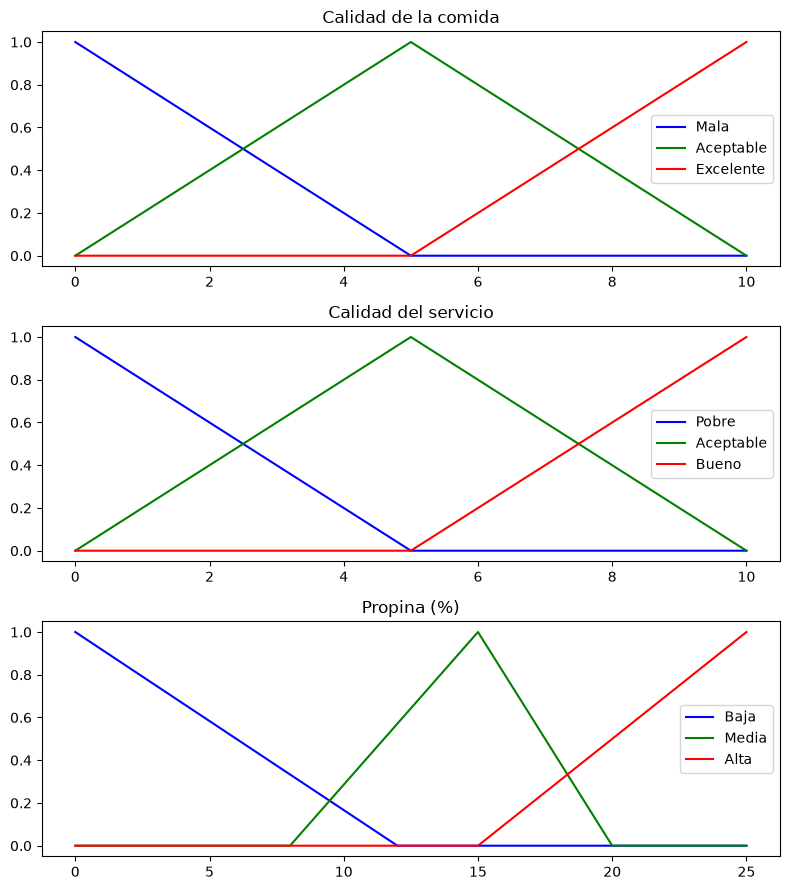

In [4]:
# Visualizamos los universos y las funciones de pertenencia
fig, (ax0, ax1, ax2) = plt.subplots(nrows=3, figsize=(8, 9))

ax0.plot(calidad.universe, calidad['mala'].mf, 'b', linewidth=1.5, label='Mala')
ax0.plot(calidad.universe, calidad['aceptable'].mf, 'g', linewidth=1.5, label='Aceptable')
ax0.plot(calidad.universe, calidad['excelente'].mf, 'r', linewidth=1.5, label='Excelente')
ax0.set_title('Calidad de la comida')
ax0.legend()

ax1.plot(servicio.universe, servicio['pobre'].mf, 'b', linewidth=1.5, label='Pobre')
ax1.plot(servicio.universe, servicio['aceptable'].mf, 'g', linewidth=1.5, label='Aceptable')
ax1.plot(servicio.universe, servicio['bueno'].mf, 'r', linewidth=1.5, label='Bueno')
ax1.set_title('Calidad del servicio')
ax1.legend()

ax2.plot(propina.universe, propina['baja'].mf, 'b', linewidth=1.5, label='Baja')
ax2.plot(propina.universe, propina['media'].mf, 'g', linewidth=1.5, label='Media')
ax2.plot(propina.universe, propina['alta'].mf, 'r', linewidth=1.5, label='Alta')
ax2.set_title('Propina (%)')
ax2.legend()

plt.tight_layout()
plt.show()

### ¿Qué muestran estos gráficos?

Cada gráfico representa una variable del problema:

- **Eje X:** el universo de discurso, es decir, los valores posibles de la variable (0-10 para calidad y servicio, 0-25 % para la propina).
- **Eje Y:** el grado de pertenencia, de 0 a 1.
- **Cada curva:** una etiqueta lingüística (azul, verde y roja, de menor a mayor).

**Calidad de la comida y calidad del servicio:** las tres etiquetas las ha creado `automf(3)`. Son triángulos repartidos de forma uniforme, con los picos en 0, 5 y 10, y cada uno se cruza con su vecino a mitad de camino. Así, cualquier valor pertenece como mucho a **dos etiquetas a la vez**, y sus grados suman 1. Por ejemplo, una calidad de 6,5 es *aceptable* en grado 0,7 y *excelente* en grado 0,3.

**Propina (%):** aquí los triángulos los hemos definido a mano con `trimf`, por eso no son simétricos ni del mismo tamaño:

- *Baja* `[0, 0, 12]`: vale 1 en 0 % y baja hasta 0 en 12 %.
- *Media* `[8, 15, 20]`: sube desde 8 %, tiene el pico en 15 % y baja hasta 0 en 20 %.
- *Alta* `[15, 25, 25]`: sube desde 15 % y vale 1 en 25 %.

Los tramos se **solapan** (8-12 % entre baja y media, 15-20 % entre media y alta). Gracias a esos solapes el paso de una etiqueta a otra es gradual y no hay huecos: cualquier valor de 0 % a 25 %, incluidos los extremos, pertenece al menos a una etiqueta.

> Para leer el gráfico, traza una línea vertical en un valor del eje X. La altura a la que corta cada curva es el grado de pertenencia de ese valor a esa etiqueta.

### Reglas difusas

Las **reglas** son el conocimiento del sistema: describen, con palabras, cómo decidiría un experto. Tienen la forma:

> **SI** *antecedente* **ENTONCES** *consecuente*

- **Antecedente:** una o varias condiciones sobre las variables de entrada, unidas con **Y** (AND), **O** (OR) o **NO** (NOT).
- **Consecuente:** la etiqueta que toma la variable de salida.

Por ejemplo, en el problema de la propina:

- **SI** la calidad es *mala* **O** el servicio es *pobre* **ENTONCES** la propina es *baja*.
- **SI** el servicio es *aceptable* **ENTONCES** la propina es *media*.
- **SI** la calidad es *excelente* **Y** el servicio es *bueno* **ENTONCES** la propina es *alta*.

A diferencia de una regla clásica, que se cumple o no se cumple, una regla difusa se cumple **en cierto grado**. Ese grado se calcula a partir de los grados de pertenencia del antecedente:

- **Y** (AND): se toma el **mínimo** de los grados.
- **O** (OR): se toma el **máximo** de los grados.
- **NO** (NOT): se calcula **1 − grado**.

Varias reglas pueden activarse a la vez, cada una con su propio grado. El sistema **combina** todas sus conclusiones y después las convierte en un único valor numérico de propina (*desdifusificación*).

En `scikit-fuzzy` cada regla se crea con `ctrl.Rule(antecedente, consecuente)`, usando los operadores `&` (Y), `|` (O) y `~` (NO). Por ejemplo: `ctrl.Rule(calidad['mala'] | servicio['pobre'], propina['baja'])`.

In [5]:
# 3. Reglas difusas
regla1 = ctrl.Rule(calidad['mala'] | servicio['pobre'], propina['baja'])
regla2 = ctrl.Rule(servicio['aceptable'], propina['media'])
regla3 = ctrl.Rule(servicio['bueno'] | calidad['excelente'], propina['alta'])

### Sistema de control y simulación

Con las variables, las funciones de pertenencia y las reglas ya definidas, falta **montar el sistema** y **usarlo** con valores concretos. Se hace en dos pasos:

- **Sistema de control:** agrupa todas las reglas en un único motor de inferencia. Es el "cerebro" del sistema: sabe *cómo* decidir, pero todavía no ha recibido ningún dato.
- **Simulación:** es una ejecución concreta del sistema. Le damos valores numéricos a las entradas (p. ej. calidad = 6,5 y servicio = 9,8) y nos devuelve el valor de la salida.

Al ejecutar la simulación, el sistema recorre las fases de la lógica difusa:

1. **Difusificación:** convierte cada valor de entrada en grados de pertenencia a sus etiquetas (*mala*, *aceptable*, …).
2. **Evaluación de reglas:** calcula en qué grado se cumple cada regla (mínimo para Y, máximo para O).
3. **Agregación:** combina las conclusiones de todas las reglas activadas en un único conjunto difuso de salida.
4. **Desdifusificación:** convierte ese conjunto difuso en un número concreto de propina. Por defecto se usa el método del **centroide** (el "centro de gravedad" del área resultante).

En `scikit-fuzzy`:

- `ctrl.ControlSystem([regla1, regla2, regla3])` crea el sistema a partir de la lista de reglas.
- `ctrl.ControlSystemSimulation(sistema)` crea una simulación de ese sistema.
- `simulacion.input['calidad'] = 6.5` asigna valores a las entradas (usando el nombre que se dio a cada variable).
- `simulacion.compute()` ejecuta todo el proceso de inferencia.
- `simulacion.output['propina']` devuelve el resultado, y `propina.view(sim=simulacion)` dibuja el área agregada y el valor final obtenido.

Propina sugerida: 21.11%


/home/jordi/Documentos/Ribera/Curso26_27/CEIABD/GITHUB/REPO/CEIABD_26_27/.venv/lib/python3.14/site-packages/skfuzzy/control/fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


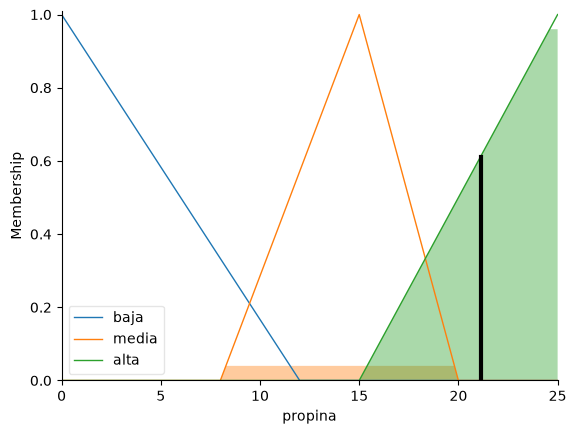

In [6]:
# 4. Sistema y simulación
sistema = ctrl.ControlSystem([regla1, regla2, regla3])
sim = ctrl.ControlSystemSimulation(sistema)
sim.input['calidad'] = 6.5
sim.input['servicio'] = 9.8
sim.compute()
print(f"Propina sugerida: {sim.output['propina']:.2f}%")
# Salida esperada: Propina sugerida: ~20% (el valor exacto depende del universo)
propina.view(sim)

### Interpretación del resultado

El gráfico que muestra `propina.view(sim)` resume **todo el proceso de inferencia** en una sola imagen:

- Las **líneas finas** son las funciones de pertenencia de la propina (*baja*, *media* y *alta*).
- El **área sombreada** es el conjunto difuso de salida: cada función de salida se "recorta" a la altura del grado con que se ha activado su regla y después se unen todas (agregación).
- La **línea vertical negra** marca el valor final obtenido por desdifusificación: el **centroide** (centro de gravedad) del área sombreada. En nuestro caso, **≈ 21,1 %**.

**¿Por qué sale ese valor?** Veamos qué ocurre con las entradas calidad = 6,5 y servicio = 9,8:

| Entrada | Grados de pertenencia |
|---|---|
| Calidad = 6,5 | mala = 0 · aceptable = 0,7 · excelente = 0,3 |
| Servicio = 9,8 | pobre = 0 · aceptable = 0,04 · bueno = 0,96 |

| Regla | Grado de activación |
|---|---|
| R1: calidad *mala* **O** servicio *pobre* → propina *baja* | máx(0; 0) = **0** |
| R2: servicio *aceptable* → propina *media* | **0,04** |
| R3: servicio *bueno* **O** calidad *excelente* → propina *alta* | máx(0,96; 0,3) = **0,96** |

La regla 3 se activa casi por completo, la 2 apenas y la 1 nada. Por eso el área sombreada se concentra sobre la zona de propina *alta* (15-25 %) y el centroide cae dentro de ella, algo por debajo del centro del triángulo (≈ 21,1 %) por el pequeño peso de la propina *media*.

**Conclusiones:**

1. **El resultado es razonable:** un servicio casi perfecto y una comida correcta llevan a una propina alta, como haría una persona.
2. **La salida es gradual, no a saltos:** el sistema no elige "alta" sin más, sino un valor concreto (21,1 %) que pondera todas las reglas según su grado de activación. Si el servicio bajara un poco, la propina bajaría también poco a poco.
3. **Las reglas determinan el comportamiento:** la calidad *aceptable* (grado 0,7, el más alto de la comida) **no aparece en ninguna regla**, así que no influye en el resultado. Aquí la propina la decide casi solo el servicio. Si queremos que la comida pese más, hay que **añadir o modificar reglas** (p. ej. *SI calidad aceptable Y servicio bueno ENTONCES propina media*).

> **Prueba:** cambia los valores de entrada (por ejemplo calidad = 2 y servicio = 3) y observa cómo se desplazan el área sombreada y la línea del centroide.

## **Ejercicio**

Realiza un sistema de control difuso para el control de inventario basado en la demanda del mercado y el inventario actual. El sistema intentará ajustar el nivel de inventario para minimizar el costo de mantener el inventario y prevenir las fluctuaciones de la demanda. Algunas reglas difusas que podría incluir son:

- Si la demanda es alta y el inventario es moderado, entonces aumentar el pedido.
- Si la demanda es baja y el inventario es alto, entonces reducir el pedido.
- Si la demanda es moderada y el inventario es moderado, entonces mantener el mismo nivel de pedido.
- Si la demanda es incierta y el inventario es bajo, entonces aumentar el pedido para prevenir una posible escasez.
- Si la demanda es incierta y el inventario es alto, entonces reducir el pedido para prevenir un exceso de inventario.

